In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".08"

In [2]:
import numpy as np
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer
from skophys.sm import NNCCA, NNSM
from skophys.datasets import ARProcessMovie
import fastplotlib as fpl
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
import seaborn as sns00
from itertools import product

fastplotlib version from git (0.5.0) and __version__ (0.5.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [3]:
%matplotlib inline

In [4]:
from skimage.transform import downscale_local_mean

In [55]:
movie = tifffile.memmap("../dendrites_rect.tif")
movie = movie[:, 10:50, 20:50]

In [56]:
movie.shape

(19999, 40, 30)

In [57]:
movie_mean = movie.mean(axis=0)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
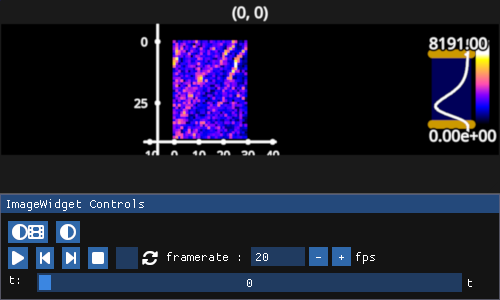

In [58]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")#, frame_apply={0: lambda f: f - movie_mean})
iw.show()

In [59]:
X = Vectorizer().transform(movie)
unvec = UnVectorizer(movie.shape[1:])

from sklearn.preprocessing import StandardScaler

X_zs = StandardScaler().fit_transform(X.T)

stds = X_zs.std(axis=1)

X_zs.shape
ixs = stds > 1
ixs

array([ True,  True,  True, ...,  True,  True,  True])

In [60]:
ixs.sum()

7756

In [61]:
nnsm = NNSM(lag=1, lag_step=1)

In [63]:
nnsm.pre_initialize(movie[ixs], max_k=20)

creating H
computing covariance
estimating k
running svd to estimate k
truncated whitening
performing nnSVD


In [64]:
nnsm._X_init.shape

(1200, 7756)

In [65]:
nnsm.pre_init_arrays.P.shape

(1200, 7755)

In [66]:
nnsm.pre_init_arrays.Y

array([[0.00983649, 0.00995517, 0.00600175, ..., 0.03277017, 0.02998899,
        0.03024844],
       [0.        , 0.        , 0.        , ..., 0.00312166, 0.00564991,
        0.00335913],
       [0.01087027, 0.00961623, 0.00940074, ..., 0.00154514, 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.00382438, 0.00126478,
        0.00109191],
       [0.0133234 , 0.01796215, 0.0135962 , ..., 0.00424242, 0.        ,
        0.00382888],
       [0.        , 0.        , 0.        , ..., 0.00560137, 0.00601914,
        0.00336462]])

In [67]:
err_log, Ys, Ws = nnsm.initialize(max_iter=5_000, keep_iteration_results=True, eta=0.1, error_threshold=1e-2)

  0%|                                                                                | 0/5000 [00:00<?, ?it/s]2025-08-05 05:52:29.500580: W external/xla/xla/tsl/framework/bfc_allocator.cc:501] Allocator (GPU_0_bfc) ran out of memory trying to allocate 229.42MiB (rounded to 240560128)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
2025-08-05 05:52:29.500672: W external/xla/xla/tsl/framework/bfc_allocator.cc:512] *****_______________________***********************************************************xxxxxxxxxxxxx
2025-08-05 05:52:29.505683: W external/xla/xla/service/gpu/autotuning/gemm_fusion_autotuner.cc:1171] Autotuning candidate failed with out of memory error. Consider disabling correctness checking (i.e. --xla_gpu_autotune_level=3) to reduce autotuning memory usage.
  0%|                                        

XlaRuntimeError: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 240560100 bytes.

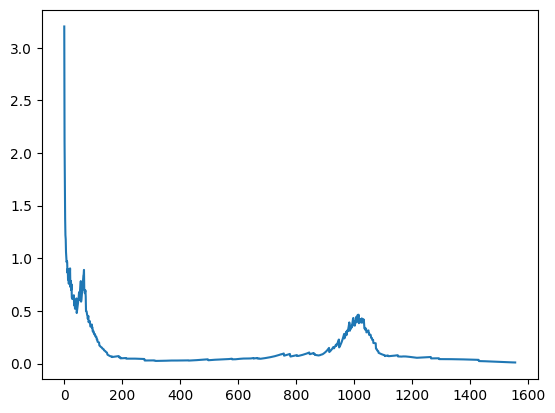

In [45]:
plt.plot(err_log)

In [46]:
err_log[-1]

0.009959009476006031

In [50]:
nnsm.lag_slices

[slice(0, 1200, None), slice(1200, 2400, None)]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='1500.0px')
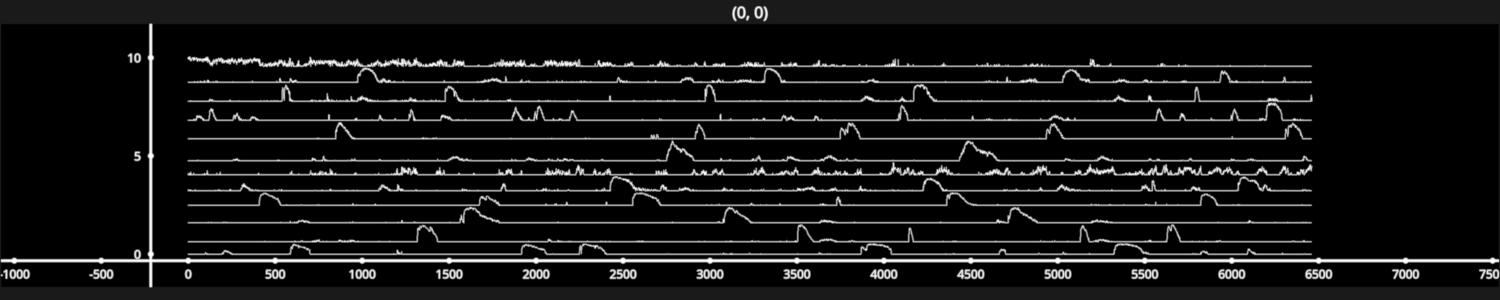

In [51]:
fig = fpl.Figure(size=(1500, 300))

fig[0, 0].add_line_stack(nnsm.init_arrays.Y / nnsm.init_arrays.Y.max(), separation=0.1, thickness=1)

for subplot in fig:
    subplot.toolbar = False

fig.show(maintain_aspect=False)

RFBOutputContext()

JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
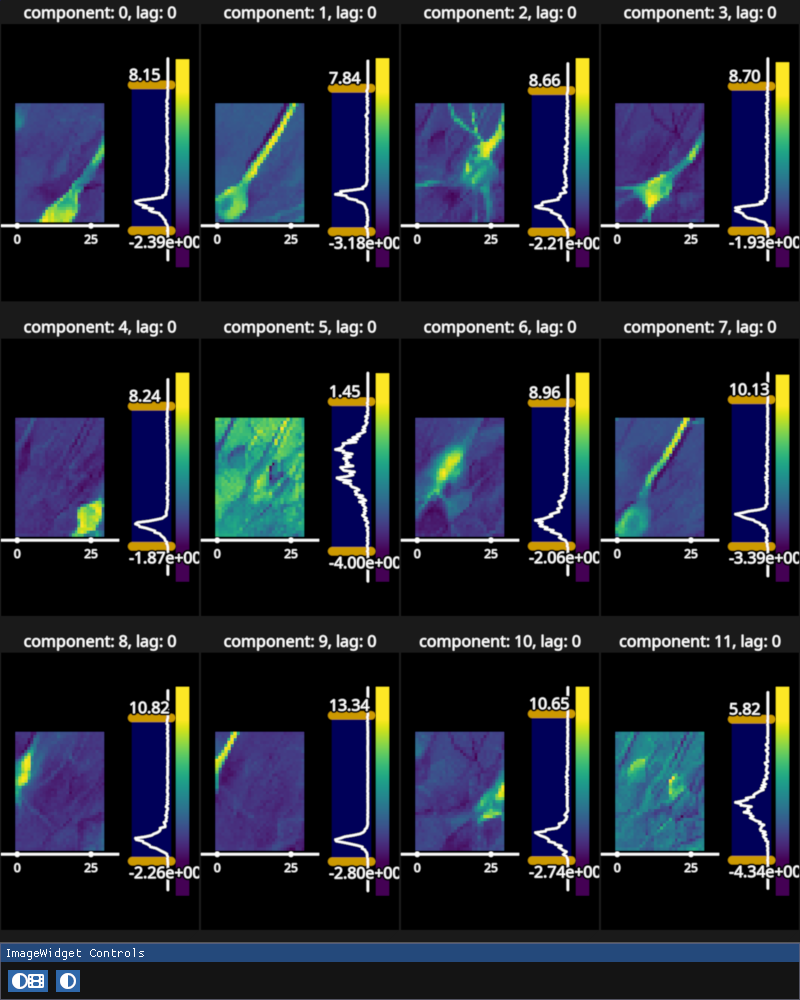

In [54]:
images, titles = list(), list(),
for k_i, l_i in product(range(nnsm.init_arrays.k), range(nnsm.lag)):
    images.append(nnsm.unvec.transform(nnsm.init_arrays.W[k_i, nnsm.lag_slices[l_i]].T))
    titles.append(f"component: {k_i}, lag: {l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    # figure_shape=(nnsm.init_arrays.k, nnsm.lag),
    figure_kwargs={"size": (800, 1000)},
)

for subplot in iw_W.figure:
    subplot.toolbar = False

# for g in iw_W.managed_graphics:
#     g.vmin = 0

iw_W.show()